<a href="https://colab.research.google.com/github/tinana2k/CS-5592---Dsng-and-Anal-Algorithms/blob/main/Assignment%201/Part%20A/notebook/Assignment1_PartA_Tina_Nguyen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 - Part A: Sorting Algorithms
**Name:** Tina Nguyen  
**Course:** COMP-SCI 5592 - Design & Analysis of Algorithms  
**Fall 2026**

For this assignment, I tested **TimSort, Quicksort, and Introsort** using the `Most English 50000 Words.txt` file. I used 25%, 50%, 75%, and 100% of the data to see how the algorithms perform as the input gets larger.

I measured the number of comparisons, the number of pairwise swaps (where available), and execution time. Then I made line charts to compare the results.

**Note:** Run the cells from top to bottom. Colab will ask you to upload the text file if it is not already uploaded.

## Step 1: Import libraries
I am using Python to run the sorting algorithms, pandas to make the results table, and matplotlib for the graphs.

In [1]:
from pathlib import Path
import csv, math, statistics, time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Folder where I will save the graphs and tables
OUTPUT_DIR = Path('Assignment1_PartA_Output')
OUTPUT_DIR.mkdir(exist_ok=True)
REPEATS = 5  # Median of five actual wall-clock measurements
print('Results will be saved to:', OUTPUT_DIR.resolve())

Results will be saved to: /content/Assignment1_PartA_Output


## Step 2: Read the dataset
I uploaded the 50,000-word text file. Each line has one word. I will use the same input words for all three algorithms so that the comparison is fair.

In [2]:
# Look for the dataset, or upload it in Google Colab
filename = 'Most English 50000 Words.txt'
possible_paths = [Path(filename), Path('/content') / filename, Path('/mnt/data') / filename]
dataset_path = next((p for p in possible_paths if p.is_file()), None)
if dataset_path is None:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(f'Place {filename} next to this notebook and rerun this cell.') from exc
    print('Please upload:', filename)
    uploaded = files.upload()
    if filename not in uploaded:
        raise FileNotFoundError(f'Upload the file named exactly {filename}')
    dataset_path = Path(filename)

words = [line.strip() for line in dataset_path.read_text(encoding='utf-8-sig').splitlines() if line.strip()]
assert len(words) == 50000, f'Expected 50,000 nonblank words; found {len(words)}'
print(f'Loaded {len(words):,} words from {dataset_path}')
print('First 10 words:', words[:10])

Loaded 50,000 words from Most English 50000 Words.txt
First 10 words: ['other', 'such', 'first', 'many', 'new', 'more', 'same', 'own', 'good', 'different']


## Step 3: Write the sorting algorithms
I used:
- **TimSort:** Python's built-in sorting algorithm.
- **Quicksort:** A three-way Quicksort with median-of-three pivot choice and insertion sort for small sections.
- **Introsort:** Starts like Quicksort and changes to heapsort when the recursion depth gets too large.

I count comparisons each time two words are compared. For the custom algorithms, I count a swap when two different positions exchange elements.

**TimSort swap count is N/A**, not zero. Python does not provide a direct pairwise-swap count for its built-in sort.

In [3]:
# Functions to count comparisons and swaps while sorting
class CountedStr:
    comparisons = 0
    def __init__(self, value): self.value = value
    def __lt__(self, other):
        CountedStr.comparisons += 1
        return self.value < other.value

def timsort(values):
    CountedStr.comparisons = 0
    data = [CountedStr(v) for v in values]
    data.sort()
    return [x.value for x in data], CountedStr.comparisons, None

class Metrics:
    def __init__(self): self.comps = 0; self.swaps = 0
    def less(self, a, b):
        self.comps += 1
        return a < b
    def swap(self, a, i, j):
        if i != j:
            a[i], a[j] = a[j], a[i]
            self.swaps += 1

def insertion(a, lo, hi, m):
    for i in range(lo+1, hi):
        j = i
        while j > lo and m.less(a[j], a[j-1]):
            m.swap(a,j,j-1); j-=1

def partition(a, lo, hi, m):
    mid = (lo+hi)//2
    # median of three, half-open interval
    if m.less(a[mid],a[lo]): m.swap(a, mid, lo)
    if m.less(a[hi-1],a[lo]): m.swap(a, hi-1, lo)
    if m.less(a[hi-1],a[mid]): m.swap(a, hi-1, mid)
    pivot = a[mid]
    lt=lo; i=lo; gt=hi
    while i<gt:
        if m.less(a[i], pivot): m.swap(a,lt,i); lt+=1; i+=1
        elif m.less(pivot,a[i]): gt-=1; m.swap(a,i,gt)
        else: i+=1
    return lt,gt

def quicksort(values):
    a=list(values); m=Metrics(); stack=[(0,len(a))]
    while stack:
        lo,hi=stack.pop()
        while hi-lo>24:
            lt,gt=partition(a,lo,hi,m)
            if lt-lo<hi-gt:
                if gt<hi: stack.append((gt,hi))
                hi=lt
            else:
                if lo<lt: stack.append((lo,lt))
                lo=gt
        insertion(a,lo,hi,m)
    return a,m.comps,m.swaps

def sift_down(a, start, end, offset, m):
    root=start
    while 2*root+1<=end:
        child=2*root+1
        if child+1<=end and m.less(a[offset+child],a[offset+child+1]): child+=1
        if not m.less(a[offset+root],a[offset+child]): break
        m.swap(a,offset+root,offset+child); root=child

def heapsort_range(a, lo, hi, m):
    n=hi-lo
    for start in range((n-2)//2,-1,-1): sift_down(a,start,n-1,lo,m)
    for end in range(n-1,0,-1):
        m.swap(a,lo,lo+end); sift_down(a,0,end-1,lo,m)

def introsort(values):
    a=list(values); m=Metrics(); depth=2*int(math.log2(len(a))) if a else 0
    stack=[(0,len(a),depth)]
    while stack:
        lo,hi,limit=stack.pop()
        while hi-lo>24:
            if limit==0:
                heapsort_range(a,lo,hi,m); break
            limit-=1
            lt,gt=partition(a,lo,hi,m)
            if lt-lo < hi-gt:
                if gt<hi: stack.append((gt,hi,limit))
                hi=lt
            else:
                if lo<lt: stack.append((lo,lt,limit))
                lo=gt
        else:
            insertion(a,lo,hi,m)
    return a,m.comps,m.swaps



## Step 4: Test the four data sizes
Now I run all three algorithms on:

| Data size | Number of words |
|---|---:|
| 25% | 12,500 |
| 50% | 25,000 |
| 75% | 37,500 |
| 100% | 50,000 |

I run each test five times and use the median time (milliseconds). `time.perf_counter_ns()` measures real elapsed time. The notebook also checks that the sorted output is correct.

In [4]:
# Run each algorithm with 25%, 50%, 75%, and 100% of the words
algorithms = {
    'TimSort (Python)': timsort,
    'Quicksort (median-of-three, 3-way)': quicksort,
    'Introsort (3-way + heapsort fallback)': introsort,
}

records = []
for percentage in (25, 50, 75, 100):
    n = len(words) * percentage // 100
    treatment = words[:n]
    reference = sorted(treatment)
    for name, sorter in algorithms.items():
        observed_ms = []
        for repeat in range(REPEATS):
            start_ns = time.perf_counter_ns()
            result, comparisons, swaps = sorter(treatment)
            elapsed_ms = (time.perf_counter_ns() - start_ns) / 1_000_000
            assert result == reference, f'Incorrect output for {name} on {percentage}%'
            observed_ms.append(elapsed_ms)
        records.append({
            'Treatment': f'{percentage}%', 'N': n, 'Algorithm': name,
            'Comparisons': comparisons,
            'Swaps': 'N/A' if swaps is None else swaps,
            'Time_ms_median': round(statistics.median(observed_ms), 3),
            'Time_ms_min': round(min(observed_ms), 3),
            'Time_ms_max': round(max(observed_ms), 3),
        })
        print(f'{percentage:>3}% | {name:<38} | {statistics.median(observed_ms):>9.3f} ms | comparisons={comparisons:,} | swaps={"N/A" if swaps is None else f"{swaps:,}"}')

results = pd.DataFrame(records)
results.to_csv(OUTPUT_DIR / 'sorting_results.csv', index=False)
print('\nAll 12 experiments passed correctness tests.')
display(results)

 25% | TimSort (Python)                       |    65.404 ms | comparisons=154,085 | swaps=N/A
 25% | Quicksort (median-of-three, 3-way)     |    68.819 ms | comparisons=272,263 | swaps=136,489
 25% | Introsort (3-way + heapsort fallback)  |    67.211 ms | comparisons=272,263 | swaps=136,489
 50% | TimSort (Python)                       |   147.264 ms | comparisons=333,008 | swaps=N/A
 50% | Quicksort (median-of-three, 3-way)     |   151.802 ms | comparisons=592,522 | swaps=291,860
 50% | Introsort (3-way + heapsort fallback)  |   147.755 ms | comparisons=592,522 | swaps=291,860
 75% | TimSort (Python)                       |   221.581 ms | comparisons=522,033 | swaps=N/A
 75% | Quicksort (median-of-three, 3-way)     |   232.674 ms | comparisons=883,750 | swaps=426,149
 75% | Introsort (3-way + heapsort fallback)  |   229.300 ms | comparisons=883,750 | swaps=426,149
100% | TimSort (Python)                       |   314.733 ms | comparisons=715,725 | swaps=N/A
100% | Quicksort (median-o

,Treatment,N,Algorithm,Comparisons,Swaps,Time_ms_median,Time_ms_min,Time_ms_max
0,25%,12500,TimSort (Python),154085,N/A,65.404,60.767,67.919
1,25%,12500,"Quicksort (median-of-three, 3-way)",272263,136489,68.819,66.847,70.785
2,25%,12500,Introsort (3-way + heapsort fallback),272263,136489,67.211,66.525,80.266
3,50%,25000,TimSort (Python),333008,N/A,147.264,138.440,356.875
4,50%,25000,"Quicksort (median-of-three, 3-way)",592522,291860,151.802,143.685,185.603
5,50%,25000,Introsort (3-way + heapsort fallback),592522,291860,147.755,144.072,157.950
6,75%,37500,TimSort (Python),522033,N/A,221.581,220.397,291.883
7,75%,37500,"Quicksort (median-of-three, 3-way)",883750,426149,232.674,221.580,241.463
8,75%,37500,Introsort (3-way + heapsort fallback),883750,426149,229.300,223.986,239.020
9,100%,50000,TimSort (Python),715725,N/A,314.733,298.050,378.173


## Step 5: Make the line charts
These graphs compare (1) comparisons, (2) swaps, and (3) execution time. I used number of words on the x-axis.

For the swaps graph, TimSort is not shown because I could not measure pairwise swaps with Python's built-in sort.

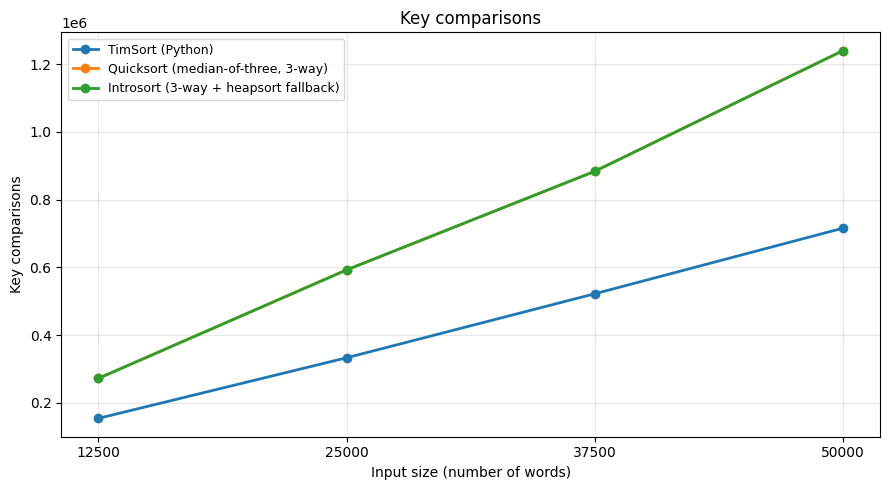

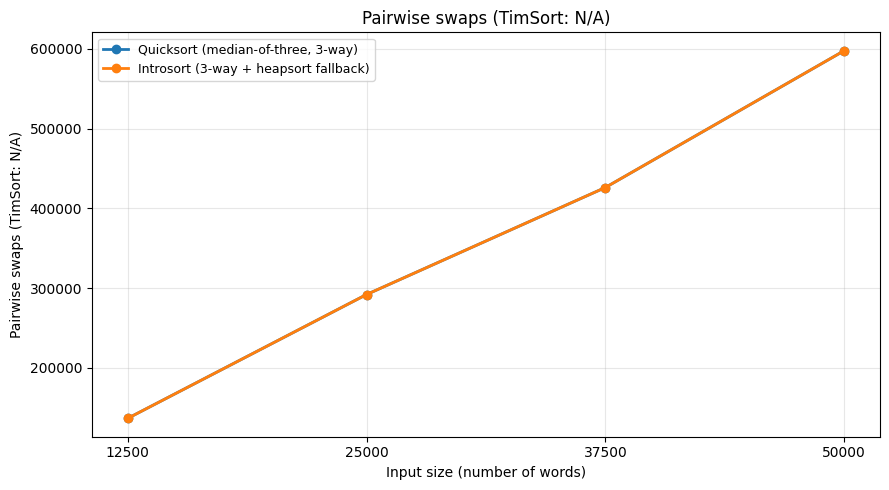

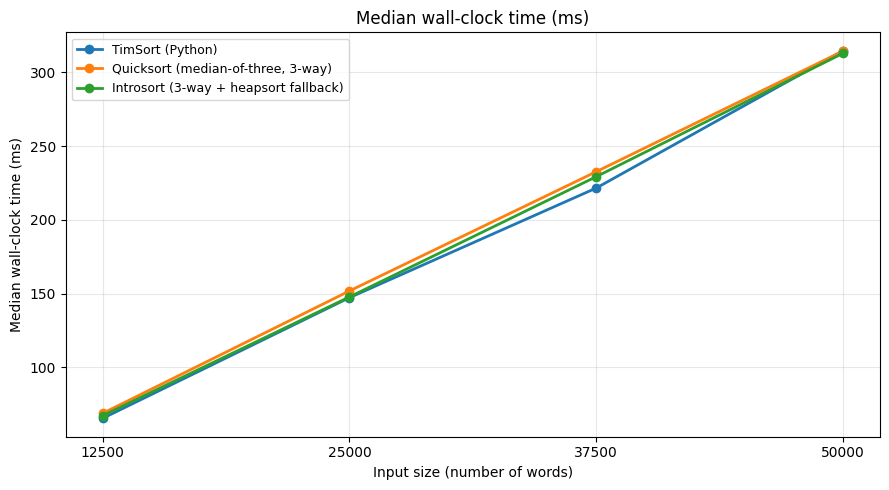

Saved charts and CSV into Assignment1_PartA_Output


In [5]:
# Plot the results from the table above
chart_specs = [
    ('Comparisons', 'Key comparisons', 'comparisons.png'),
    ('Swaps', 'Pairwise swaps (TimSort: N/A)', 'swaps.png'),
    ('Time_ms_median', 'Median wall-clock time (ms)', 'runtime.png'),
]
for column, title, filename in chart_specs:
    fig, ax = plt.subplots(figsize=(9, 5))
    for name in algorithms:
        selection = results[results['Algorithm'] == name].sort_values('N')
        y = pd.to_numeric(selection[column], errors='coerce')
        if y.notna().any():
            ax.plot(selection['N'], y, marker='o', linewidth=2, label=name)
    ax.set_title(title)
    ax.set_xlabel('Input size (number of words)')
    ax.set_ylabel(title)
    ax.set_xticks([12500, 25000, 37500, 50000])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=160)
    plt.show()
    plt.close(fig)
print('Saved charts and CSV into', OUTPUT_DIR)

## Step 6: Space complexity

| Algorithm | Extra space used by the sorting method |
|---|---|
| TimSort | Up to O(n) for temporary storage |
| Quicksort (this version) | O(log n) stack in the worst case because it processes the smaller side first |
| Introsort (this version) | O(log n) stack with a heapsort fallback |

My code also makes a copy of the input before sorting, so **each algorithm uses O(n) total extra space if that copy is included**.

## Step 7: Scalability
Here I compare the time at 12,500 words with the time at 50,000 words. This helps me see how much slower each algorithm becomes when the input size increases.

In [6]:
pivot = results.pivot(index='N', columns='Algorithm', values='Time_ms_median')
display(pivot.round(3))
ratios = pivot.loc[50000] / pivot.loc[12500]
print('Growth in wall-clock time from 12,500 to 50,000 words:')
for name, ratio in ratios.items():
    print(f'  {name}: {ratio:.2f}x')
fastest_full = pivot.loc[50000].idxmin()
print(f'Fastest measured implementation for the 100% treatment: {fastest_full}')
print('Typical theoretical worst-case bounds: TimSort O(n log n); Introsort O(n log n); Quicksort O(n²) worst case (expected O(n log n) under favorable partitioning).')

Algorithm,Introsort (3-way + heapsort fallback),"Quicksort (median-of-three, 3-way)",TimSort (Python)
N,,,
12500,67.211,68.819,65.404
25000,147.755,151.802,147.264
37500,229.300,232.674,221.581
50000,312.998,314.489,314.733


Growth in wall-clock time from 12,500 to 50,000 words:
  Introsort (3-way + heapsort fallback): 4.66x
  Quicksort (median-of-three, 3-way): 4.57x
  TimSort (Python): 4.81x
Fastest measured implementation for the 100% treatment: Introsort (3-way + heapsort fallback)
Typical theoretical worst-case bounds: TimSort O(n log n); Introsort O(n log n); Quicksort O(n²) worst case (expected O(n log n) under favorable partitioning).


## Step 8: Test different input orders
To see how input order matters, I also tested the first 12,500 words in four ways: original order, sorted order, reverse order, and shuffled order.

This helps me understand adaptive behavior. TimSort often benefits when the data already has ordered parts. The actual results depend on the input and Colab runtime.

In [8]:
# Try different input orders using the same 12,500 words
import random
rng = random.Random(3619)
base = words[:12500]
shuffled = base.copy()
rng.shuffle(shuffled)
variants = {
    'Original order': base,
    'Already sorted': sorted(base),
    'Reverse sorted': sorted(base, reverse=True),
    'Shuffled': shuffled,
}
adaptive_rows = []
for case, data in variants.items():
    expected = sorted(data)
    for name, sorter in algorithms.items():
        timings = []
        for _ in range(3):
            t0 = time.perf_counter_ns()
            output, comparisons, swaps = sorter(data)
            timings.append((time.perf_counter_ns()-t0)/1e6)
            assert output == expected
        adaptive_rows.append({'Input Order': case, 'Algorithm': name,
                              'Comparisons': comparisons, 'Swaps': 'N/A' if swaps is None else swaps,
                              'Median Time (ms)': round(statistics.median(timings), 3)})
adaptive_df = pd.DataFrame(adaptive_rows)
adaptive_df.to_csv(OUTPUT_DIR / 'adaptive_results.csv', index=False)
display(adaptive_df)
print('TimSort can exploit pre-existing ordered runs; compare comparisons and times to see the measured effect.')

,Input Order,Algorithm,Comparisons,Swaps,Median Time (ms)
0,Original order,TimSort (Python),154085,N/A,88.216
1,Original order,"Quicksort (median-of-three, 3-way)",272263,136489,67.751
2,Original order,Introsort (3-way + heapsort fallback),272263,136489,74.259
3,Already sorted,TimSort (Python),12499,N/A,20.184
4,Already sorted,"Quicksort (median-of-three, 3-way)",1497677,742116,333.072
5,Already sorted,Introsort (3-way + heapsort fallback),834561,420620,477.342
6,Reverse sorted,TimSort (Python),12499,N/A,34.264
7,Reverse sorted,"Quicksort (median-of-three, 3-way)",1082708,531660,685.039
8,Reverse sorted,Introsort (3-way + heapsort fallback),764481,381238,547.795
9,Shuffled,TimSort (Python),153931,N/A,94.542


TimSort can exploit pre-existing ordered runs; compare comparisons and times to see the measured effect.


## Step 9: My conclusion
From this experiment, I learned that the performance of sorting algorithms changes as the dataset grows. I used the same four input sizes for TimSort, Quicksort, and Introsort. The tables and charts above show how their comparison counts, swaps, and running times are different.

**After I run the notebook, I will check my table and describe which algorithm was fastest in my own Colab run.** TimSort may be faster on data that is already partly sorted, while Introsort helps avoid the worst behavior of Quicksort by switching to heapsort.

One limitation is that TimSort does not give a pairwise swap count, so I listed it as N/A instead of making up a number. Also, the exact timing results can change on a different computer.

## Step 10: Download my results
This cell puts the result tables and the three charts into a ZIP file so I can download everything together.

In [9]:
import shutil
archive_file = shutil.make_archive('Assignment1_PartA_Results', 'zip', OUTPUT_DIR)
print('Created:', archive_file)
try:
    from google.colab import files
    files.download(archive_file)
except ImportError:
    print('Not running in Colab. Find the ZIP in your current working directory.')

Created: /content/Assignment1_PartA_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>